# 10 — Telco: What does the global score hide?
**Session 6 · Objective:** Ask what happens if the model looks good overall but fails where detection matters. Compare monthly and longer contracts using probability calibration, sample support and action consequences.

These are exploratory validation diagnostics, not a newly validated group policy. A single outcome does not reveal an individual's true probability.

In [1]:
# Locate the course CSV relative to this notebook, on any operating system.
from pathlib import Path
# Verify that we are using exactly the same CSV bytes as the classroom.
import hashlib
# Report the Python version alongside the numerical results.
import platform
# Work with probability arrays, logarithms and reproducible random samples.
import numpy as np
# Keep customer data and result tables labelled by meaningful column names.
import pandas as pd
# Build the plots step by step, with explicit axes and units.
import matplotlib.pyplot as plt
# Report the installed learning-library version for reproducibility.
import sklearn
# Display more than one table from the same cell.
from IPython.display import display
# Create a fresh, unfitted copy of a model before another training run.
from sklearn.base import clone
# Apply different preprocessing to numeric and categorical inputs.
from sklearn.compose import ColumnTransformer
# Learn missing-value replacements from training customers only.
from sklearn.impute import SimpleImputer
# Keep the Logistic Regression algorithm fixed while testing inputs or policies.
from sklearn.linear_model import LogisticRegression
# Split customers reproducibly and keep churn proportions similar across folds.
from sklearn.model_selection import train_test_split, StratifiedKFold
# Fit preprocessing and the classifier within the same training boundary.
from sklearn.pipeline import Pipeline

# Scale measured quantities, encode categories and apply row-wise log formulas.
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

# Evaluate ranking with Average Precision rather than accuracy at an arbitrary cutoff.
from sklearn.metrics import average_precision_score

# Fit probability corrections on fitting folds without using validation outcomes.
from sklearn.calibration import CalibratedClassifierCV
# Measure probability error separately from ranking quality.
from sklearn.metrics import brier_score_loss, roc_auc_score

In [2]:
# Print the actual environment; do not assume it matches the instructor's versions.
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__})
# Use readable default figures and remove the two unnecessary border lines.
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

# Show campaign euros in full instead of scientific notation.
pd.options.display.float_format = '{:,.4f}'.format

{'Python': '3.12.9', 'NumPy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1'}


## Rebuild the classroom experiment
Notebook 03 reserved a 20% holdout; notebooks 06–08 kept it closed. Session 6 introduces its evaluation **after** calibration and policy choices on validation. The classroom materials already inspected this holdout: this reproduction is not a new, untouched confirmation.

Split development again into fitting and validation. Calibration uses five shuffled stratified folds **inside fitting only**, seed 606, `ensemble=False`: out-of-fold scores train the correction and the base estimator is refitted on all fitting rows. Validation chooses the correction and cutoffs. Refit on development later, keeping those choices fixed.

The SHA-256 below matches the v4 evidence file byte for byte. Numeric parsing is row-wise; medians, scales and categories are learned inside each Pipeline. Sample sizes and bin support stay in actual customers. Campaign totals are displayed per million of the corresponding population; extrapolation creates no extra observations.

In [3]:
# Point from notebooks/ to the CSV committed with this repository.
data_path = Path('../data/telco.csv')
# Fingerprint the file before cleaning so byte-for-byte identity can be checked.
fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
# This reference identifies the dataset; it is not a fitted result.
class_fingerprint = '88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a'
# Stop if the dataset changed instead of silently comparing incompatible figures.
assert fingerprint == class_fingerprint, 'Dataset differs from class; investigate first.'
# Keep the verified fingerprint visible in the saved output.
print('Dataset SHA-256:', fingerprint)
# Load one row per customer.
df = pd.read_csv(data_path)
# Confirm the expected size and that customers have not been duplicated.
assert df.shape == (7043, 21) and df.customerID.is_unique
# Parse each charge independently; the eleven blank strings become missing values.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# Exclude both the answer and the identifier from the model inputs.
X = df.drop(columns=['Churn', 'customerID'])
# Encode observed churn as 1 and staying as 0.
y = df['Churn'].eq('Yes').astype(int)

Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


In [4]:
# Reserve the same 20% holdout as notebook 03 before fitting any transformation.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=.20, stratify=y, random_state=42
)
# Use validation to choose corrections and cutoffs; keep fitting customers separate.
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=.30, stratify=y_dev, random_state=606
)
# Check the four sample sizes from the classroom protocol.
assert (len(X_dev), len(X_test), len(X_fit), len(X_valid)) == (5634, 1409, 3943, 1691)
# Check that fitting and validation do not share customers.
assert set(X_fit.index).isdisjoint(X_valid.index)
# Check that the holdout stays outside all development decisions.
assert set(X_dev.index).isdisjoint(X_test.index)
# Check that the inner split accounts for every development customer exactly once.
assert set(X_fit.index) | set(X_valid.index) == set(X_dev.index)
# Check input/outcome order at each boundary before converting anything to arrays.
for features, labels in [(X_fit, y_fit), (X_valid, y_valid), (X_test, y_test)]:
    # Equal indices mean row i describes the same customer on both sides.
    assert features.index.equals(labels.index)
# Display actual sample sizes; these are not extrapolated campaign counts.
display(pd.Series({'Development n': len(X_dev), 'Holdout n': len(X_test),
                   'Fitting n': len(X_fit), 'Validation n': len(X_valid)}))

Development n    5634
Holdout n        1409
Fitting n        3943
Validation n     1691
dtype: int64

## Hold the algorithm fixed; change two inputs
The first model uses original inputs. The finalist retains them and adds `log1p(tenure)` and `log1p(TotalCharges)`. These row-wise logs express diminishing changes and learn no population statistics. This is **not** notebook 07's Logistic +logs versus XGBoost +polynomials comparison. `SeniorCitizen` is categorical despite its 0/1 storage.

In [5]:
# Name the measured quantities explicitly; SeniorCitizen is a category, not a measurement.
NUMERIC = ['tenure', 'MonthlyCharges', 'TotalCharges']
# Collect all remaining original inputs as categorical columns.
CATEGORICAL = []
# Inspect each original column rather than inferring its role from its storage type.
for column in X.columns:
    # Anything outside the three measured quantities is one-hot encoded.
    if column not in NUMERIC:
        # Retain column order so the transformed model inputs stay reproducible.
        CATEGORICAL.append(column)
# Make the course's treatment of the stored 0/1 field explicit.
assert 'SeniorCitizen' in CATEGORICAL

# Define only the row-wise formula; it learns no statistics from other customers.
def add_logs(frame):
    # Copy inputs so another candidate can still use the original columns unchanged.
    result = frame.copy()
    # Compress tenure changes while allowing tenure zero: log1p(x) means log(1 + x).
    result['log_tenure'] = np.log1p(result['tenure'])
    # Missing total charges remain missing until the training imputer handles them.
    result['log_total'] = np.log1p(result['TotalCharges'])
    # Return originals plus the two added inputs.
    return result

In [6]:
# Rebuild an unfitted Pipeline each time so candidates do not share learned statistics.
def build_model(logs=False):
    # Begin with the original three measured quantities.
    numeric_columns = list(NUMERIC)
    # The baseline passes original inputs straight through.
    feature_step = 'passthrough'
    # Add logs only for the augmented candidate, retaining the original inputs.
    if logs:
        # Route the two derived numeric columns through the numeric branch too.
        numeric_columns.extend(['log_tenure', 'log_total'])
        # Adapt the simple row-wise function to the Pipeline's fit/transform interface.
        feature_step = FunctionTransformer(add_logs)
    # Learn numeric replacements and scales inside each training partition.
    numeric_preprocessing = Pipeline([
        ('impute', SimpleImputer(strategy='median')),  # Training medians replace missing values.
        ('scale', StandardScaler())  # Training means and standard deviations set the scale.
    ])
    # Keep categorical encoding separate from measured quantities.
    preprocessing = ColumnTransformer([
        ('num', numeric_preprocessing, numeric_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)
    ])
    # Keep the regularization and optimizer identical for the two candidates.
    classifier = LogisticRegression(C=1, solver='lbfgs', max_iter=2000)
    # Fit the feature step, preprocessing and classifier within the same boundary.
    return Pipeline([('features', feature_step), ('preprocess', preprocessing),
                     ('model', classifier)])

## Reproduce the validation choice
Rebuild the corrections independently so this notebook needs no state from notebook 09. The lowest validation Brier selects the method; keeping raw probabilities is a valid outcome.

In [7]:
# Fit the original-input reference using fitting customers only.
models = {}
# A separate Pipeline prevents learned preprocessing from being shared across models.
models['original'] = build_model(False).fit(X_fit, y_fit)
# Fit the augmented model before applying any probability correction.
models['raw'] = build_model(True).fit(X_fit, y_fit)
# Keep calibration folds entirely inside fitting, not validation.
cv = StratifiedKFold(5, shuffle=True, random_state=606)
# Audit each internal split before fitting the corrections.
for train_positions, calibration_positions in cv.split(X_fit, y_fit):
    # No customer may train the base model that produces their calibration-fold score.
    assert set(train_positions).isdisjoint(calibration_positions)
# Fit each correction from out-of-fold fitting scores, then refit its base model on fitting.
for method in ['sigmoid', 'isotonic']:
    # ensemble=False gives a single refitted base estimator and its learned correction.
    calibrated_model = CalibratedClassifierCV(
        build_model(True), method=method, cv=cv, ensemble=False
    )
    # Validation labels never enter this fit.
    models[method] = calibrated_model.fit(X_fit, y_fit)

In [8]:
# Store one aligned probability array per model for the same validation customers.
prob_valid = {}
# Collect readable metric rows instead of nesting table-building comprehensions.
metric_rows = []
# Score every fitted candidate without refitting on validation.
for name, model in models.items():
    # Column 1 is the probability of the churn class, not a binary decision.
    probabilities = model.predict_proba(X_valid)[:, 1]
    # Keep these probabilities for bin diagnostics and policy comparisons.
    prob_valid[name] = probabilities
    # Check customer count before pairing predictions with outcomes.
    assert len(probabilities) == len(y_valid)
    # Reject missing, infinite or out-of-range probabilities.
    assert np.isfinite(probabilities).all()
    # All numerical probability values must lie between zero and one.
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    # Compute probability error and two ranking summaries on identical customers.
    metric_rows.append({'Model': name,
                        'Brier': brier_score_loss(y_valid, probabilities),
                        'AP': average_precision_score(y_valid, probabilities),
                        'ROC AUC': roc_auc_score(y_valid, probabilities)})
# Put model names on the table's row labels.
validation_metrics = pd.DataFrame(metric_rows).set_index('Model')
# Start with raw probabilities so an exact tie keeps the simpler method.
selected_method = 'raw'
# Consider corrections in a fixed order without letting holdout results choose one.
for method in ['sigmoid', 'isotonic']:
    # Replace the current choice only if validation Brier is strictly smaller.
    if validation_metrics.loc[method, 'Brier'] < validation_metrics.loc[selected_method, 'Brier']:
        # Remember the validation choice for later refitting, not the fitted weights.
        selected_method = method
# Show all candidates, including corrections that fail to improve probability quality.
display(validation_metrics.round(6))
# Make the fixed selection visible before any holdout evaluation.
print('Validation choice:', selected_method)

,Brier,AP,ROC AUC
Model,,,
original,0.1318,0.6656,0.8567
raw,0.1296,0.6757,0.8615
sigmoid,0.1297,0.6757,0.8615
isotonic,0.1309,0.6610,0.8608


Validation choice: raw


In [9]:
# Repeat the same fixed-bin calculation for each model or contract group.
def bin_table(labels, probabilities):
    # Use positional arrays so one mask selects matching outcomes and probabilities.
    labels = np.asarray(labels)
    # Preserve prediction order when applying the bin boundaries.
    probabilities = np.asarray(probabilities)
    # Store all eight bins, including empty ones, to make support gaps visible.
    rows = []
    # Eight equal-width bins partition the probability scale into steps of 0.125.
    for bin_number in range(8):
        # The left edge is included in this bin.
        left = bin_number / 8
        # Normally the right edge belongs to the next bin.
        right = (bin_number + 1) / 8
        # Select customers whose predictions fall inside these boundaries.
        in_bin = (probabilities >= left) & (probabilities < right)
        # Include probability exactly 1 in the final bin.
        if bin_number == 7:
            # There is no ninth bin for customers at probability one.
            in_bin = (probabilities >= left) & (probabilities <= right)
        # Keep actual support; do not scale bin samples to a million.
        customers = int(in_bin.sum())
        # Count observed churn among the same selected customers.
        churns = int(labels[in_bin].sum())
        # Leave undefined rates visibly missing for empty bins.
        row = {'Bin left': left, 'Bin right': right, 'Customers': customers,
               'Churns': churns, 'Mean predicted': np.nan, 'Observed rate': np.nan,
               'Wilson low': np.nan, 'Wilson high': np.nan}
        # A probability mean and an observed frequency require at least one customer.
        if customers > 0:
            # Average the model probabilities rather than using the bin midpoint.
            row['Mean predicted'] = probabilities[in_bin].mean()
            # Estimate the observed frequency from the actual bin outcomes.
            rate = churns / customers
            # Retain the point estimate in natural probability units.
            row['Observed rate'] = rate
            # A normal 97.5% quantile gives the two-sided 95% Wilson interval.
            z = 1.96
            # Wilson adjusts the denominator for finite sample size.
            denominator = 1 + z*z/customers
            # Its center differs from the raw frequency, particularly for small bins.
            center = (rate + z*z/(2*customers)) / denominator
            # Compute the half-width, including uncertainty even when no event occurs.
            half_width = z * np.sqrt(
                rate*(1-rate)/customers + z*z/(4*customers*customers)
            ) / denominator
            # Keep both endpoints inside the possible frequency range.
            row['Wilson low'] = max(0, center-half_width)
            # Apply the same range restriction to the upper endpoint.
            row['Wilson high'] = min(1, center+half_width)
        # Save this bin even if it has no customers.
        rows.append(row)
    # Label the numerical results for inspection and plotting.
    result = pd.DataFrame(rows)
    # Each customer must appear in exactly one bin.
    assert result['Customers'].sum() == len(labels)
    # Binning must not lose or duplicate any observed churn.
    assert result['Churns'].sum() == labels.sum()
    # Return the audit table as well as the quantities needed for a reliability plot.
    return result

In [10]:
# Keep one plotting helper because every reliability panel uses the same axes and intervals.
def reliability(ax, table, label):
    # Empty bins have no frequency estimate and must not be drawn as zero-risk points.
    populated = table[table['Customers'] > 0]
    # Matplotlib needs distances from the point, rather than interval endpoints.
    lower_error = populated['Observed rate'] - populated['Wilson low']
    # Compute the upper error-bar distance separately for readability.
    upper_error = populated['Wilson high'] - populated['Observed rate']
    # Draw mean predicted risk against observed frequency with Wilson uncertainty.
    ax.errorbar(populated['Mean predicted'], populated['Observed rate'],
                yerr=[lower_error, upper_error], marker='o', capsize=3, label=label)
    # The diagonal is the reference where mean risk equals observed frequency.
    ax.plot([0, 1], [0, 1], '--', color='grey')
    # Use the complete probability range on both axes so panels are comparable.
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted churn probability',
           ylabel='Observed churn frequency')
    # Identify the model or customer group represented by the points.
    ax.legend()

In [11]:
# Explore the same predefined cutoff grid for both contract groups.
CUTOFFS = np.arange(1, 11) / 10

# Count policy outcomes; economics is introduced separately in notebook 11.
def detection_counts(labels, selected):
    # Convert observed outcomes into a mask that marks churners.
    churned = np.asarray(labels).astype(bool)
    # Keep offer choices in the same customer order.
    selected = np.asarray(selected).astype(bool)
    # Prevent accidental comparisons of different customer populations.
    assert churned.shape == selected.shape
    # Count observed churners receiving an offer.
    true_positives = int((churned & selected).sum())
    # Count offers to customers observed to stay.
    false_positives = int((~churned & selected).sum())
    # Count observed churners left without an offer.
    false_negatives = int((churned & ~selected).sum())
    # Divide detections by observed churns to obtain recall for this group.
    recall = true_positives / (true_positives + false_negatives)
    # Return actual counts; the display conversion uses each group's denominator.
    return {'Offers': int(selected.sum()), 'TP': true_positives, 'FP': false_positives,
            'FN': false_negatives, 'Recall': recall}

In [12]:
# Keep unit conversion separate so raw sample totals remain available for audit.
def per_million(table, population_size):
    # Copy rather than overwriting the original campaign results.
    result = table.copy()
    # Use the actual validation, holdout or group denominator supplied by the caller.
    factor = 1_000_000 / population_size
    # Only campaign totals change units; recall and probability cutoffs do not.
    for column in ['Offers', 'TP', 'FP', 'FN', 'Value EUR']:
        # Some tables contain only detection counts and no economic calculation.
        if column in result.columns:
            # Apply the same conversion to every row in this population.
            result[column] = result[column] * factor
            # Include the reporting basis in the column label.
            result = result.rename(columns={column: column + ' / million'})
    # Return the presentation table without changing the original.
    return result

## Look at support before interpreting a curve
Each group uses bins of width 0.125, including empty bins. Tables retain **actual** customer and churn counts for audit. Predicted means and observed frequencies use natural probability units; Wilson intervals reflect limited bin support. A matching group average cannot establish calibration over its whole risk range.

In [13]:
# Build mutually exclusive contract groups from the same validation input rows.
groups = {'Monthly': X_valid['Contract'].eq('Month-to-month').to_numpy(),
          'Longer contract': X_valid['Contract'].ne('Month-to-month').to_numpy()}
# Preserve the row order used by the probability arrays.
labels = y_valid.to_numpy()
# Use the method already chosen by global validation Brier.
probabilities = prob_valid[selected_method]
# Retain each group's full bin table for plotting and audit.
group_bins = {}
# Collect group-level summaries without combining them with campaign totals.
group_summary = []
# Apply each mask to both outcomes and probabilities.
for name, in_group in groups.items():
    # Keep actual bin support and Wilson bounds for this group.
    table = bin_table(labels[in_group], probabilities[in_group])
    # Save the calculation so plotting does not hide or repeat it.
    group_bins[name] = table
    # Identify the population used by the next table.
    print(name, '- actual bin support')
    # Display empty bins too: no customers means no estimated rate.
    display(table.round(4))
    # Record actual sample counts separately from extrapolated campaign counts.
    group_summary.append({'Group': name, 'Actual n': int(in_group.sum()),
                          'Actual churns': int(labels[in_group].sum()),
                          'Mean predicted': probabilities[in_group].mean(),
                          'Observed churn rate': labels[in_group].mean(),
                          'Brier': brier_score_loss(labels[in_group], probabilities[in_group])})
# Keep group names on the summary row labels for direct lookups.
summary = pd.DataFrame(group_summary).set_index('Group')
# Compare probability means, observed means and Brier without calling them equivalent.
display(summary.round(5))
# Check the actual classroom population before interpreting group differences.
assert summary.loc['Monthly', 'Actual n'] == 940
# Monthly-contract customers contain most observed validation churns.
assert summary.loc['Monthly', 'Actual churns'] == 400
# Longer contracts have their own smaller event sample.
assert summary.loc['Longer contract', 'Actual n'] == 751
# Zero detections at one cutoff must not be confused with zero observed churns.
assert summary.loc['Longer contract', 'Actual churns'] == 49

Monthly - actual bin support


,Bin left,Bin right,Customers,Churns,Mean predicted,Observed rate,Wilson low,Wilson high
0,0.0000,0.1250,92,8,0.0845,0.0870,0.0447,0.1623
1,0.1250,0.2500,170,27,0.1897,0.1588,0.1115,0.2212
2,0.2500,0.3750,190,61,0.3085,0.3211,0.2588,0.3904
3,0.3750,0.5000,147,67,0.4384,0.4558,0.3774,0.5364
4,0.5000,0.6250,136,90,0.5614,0.6618,0.5788,0.7359
5,0.6250,0.7500,101,61,0.6889,0.6040,0.5065,0.6938
6,0.7500,0.8750,90,74,0.8036,0.8222,0.7306,0.8875
7,0.8750,1.0000,14,12,0.9076,0.8571,0.6006,0.9599


Longer contract - actual bin support


,Bin left,Bin right,Customers,Churns,Mean predicted,Observed rate,Wilson low,Wilson high
0,0.0000,0.1250,615,22,0.0414,0.0358,0.0237,0.0536
1,0.1250,0.2500,105,21,0.1743,0.2000,0.1347,0.2865
2,0.2500,0.3750,26,6,0.2896,0.2308,0.1103,0.4205
3,0.3750,0.5000,4,0,0.4139,0.0000,0.0000,0.4899
4,0.5000,0.6250,1,0,0.5773,0.0000,0.0000,0.7935
5,0.6250,0.7500,0,0,NaN,NaN,NaN,NaN
6,0.7500,0.8750,0,0,NaN,NaN,NaN,NaN
7,0.8750,1.0000,0,0,NaN,NaN,NaN,NaN


,Actual n,Actual churns,Mean predicted,Observed churn rate,Brier
Group,,,,,
Monthly,940,400,0.4192,0.4255,0.1884
Longer contract,751,49,0.0712,0.0653,0.0560


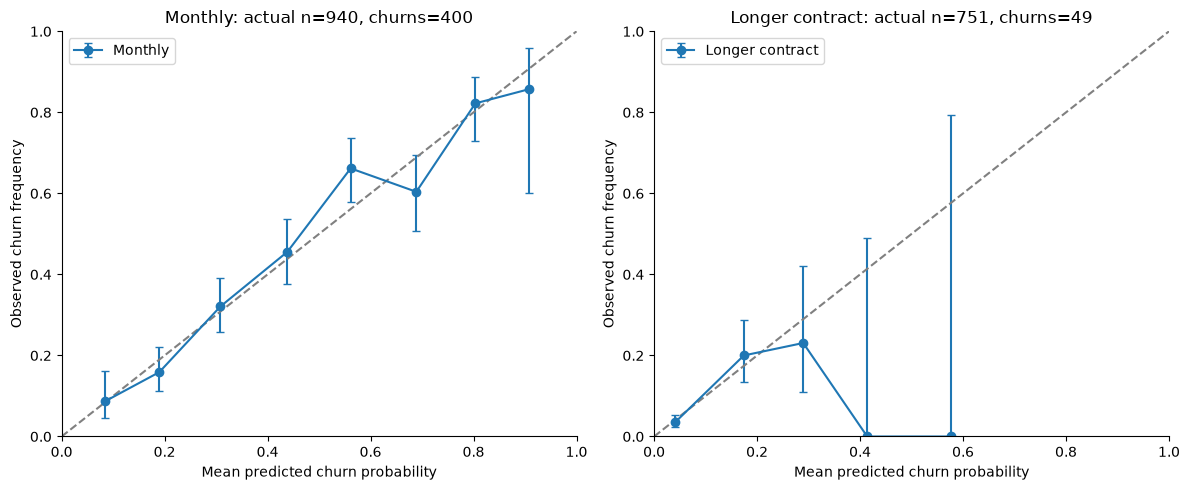

In [14]:
# Use equal scales so a group's curve is not exaggerated by a different axis range.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Draw one independently labelled panel per contract group.
for ax, (name, table) in zip(axes, group_bins.items()):
    # Plot frequencies and Wilson bounds using the previously displayed bin table.
    reliability(ax, table, name)
    # Retrieve actual population support for this panel's title.
    customers = int(summary.loc[name, 'Actual n'])
    # Retrieve the actual number of churns, not a per-million extrapolation.
    churns = int(summary.loc[name, 'Actual churns'])
    # Show the available evidence beside the curve.
    ax.set_title(f'{name}: actual n={customers}, churns={churns}')
# Keep labels legible inside the saved image.
plt.tight_layout()
# Display the group comparison after its supporting tables.
plt.show()

**Observation:** Monthly contracts concentrate churn; longer contracts contain fewer events. High-risk bins among longer contracts can contain very few customers and zero observed churns. Zero events in a tiny bin does not imply zero underlying risk: inspect its upper Wilson bound. There is no universal deviation from the diagonal that automatically declares calibration acceptable.

**Question:** Which gaps have enough support to investigate, and which would need more independent customers? Could globally acceptable probabilities still lead to poor detection under one cutoff?

## Separate calibration from detection
For each cutoff 0.1 through 1.0, every customer at or above the cutoff receives an offer. TP is churn reached, FP is an offer to an observed stayer, FN is churn missed. Recall is TP/(TP+FN). Offer counts are not retention effects.

Campaign counts below are **per million customers of that group**, using each group's actual denominator. Raw counts remain in `group_cutoffs_raw`. They are separate from the actual support shown above.

In [15]:
# Store actual counts for each combination of group and cutoff.
rows = []
# Use the same candidate cutoffs for both groups.
for name, in_group in groups.items():
    # Explore detection without introducing retention-effect assumptions.
    for cutoff in CUTOFFS:
        # Offer to all customers at or above the risk cutoff.
        selected = probabilities[in_group] >= cutoff
        # Count detections and errors on matching customer rows.
        row = detection_counts(labels[in_group], selected)
        # Label the population represented by this row.
        row['Group'] = name
        # Keep the risk cutoff in natural probability units.
        row['Cutoff'] = cutoff
        # Save the actual-sample calculation for audit.
        rows.append(row)
# Keep this unscaled table even though campaign reports use per-million units.
group_cutoffs_raw = pd.DataFrame(rows)
# Convert each group using its own denominator, not the full validation size.
for name, in_group in groups.items():
    # Select the ten rows belonging to this population.
    group_results = group_cutoffs_raw[group_cutoffs_raw['Group'] == name]
    # Scale campaign counts while leaving recall and cutoffs unchanged.
    scaled = per_million(group_results, int(in_group.sum()))
    # State the denominator explicitly before presenting extrapolated counts.
    print(name, '- per million customers OF THIS GROUP; actual n =', int(in_group.sum()))
    # Display all cutoffs, including the zero-offer policy at 1.0.
    display(scaled.round(3))

Monthly - per million customers OF THIS GROUP; actual n = 940


,Offers / million,TP / million,FP / million,FN / million,Recall,Group,Cutoff
0,"926,595.7450","420,212.7660","506,382.9790","5,319.1490",0.9880,Monthly,0.1000
1,"795,744.6810","402,127.6600","393,617.0210","23,404.2550",0.9450,Monthly,0.2000
2,"630,851.0640","369,148.9360","261,702.1280","56,382.9790",0.8680,Monthly,0.3000
3,"490,425.5320","314,893.6170","175,531.9150","110,638.2980",0.7400,Monthly,0.4000
4,"362,765.9570","252,127.6600","110,638.2980","173,404.2550",0.5920,Monthly,0.5000
5,"245,744.6810","176,595.7450","69,148.9360","248,936.1700",0.4150,Monthly,0.6000
6,"153,191.4890","114,893.6170","38,297.8720","310,638.2980",0.2700,Monthly,0.7000
7,"68,085.1060","59,574.4680","8,510.6380","365,957.4470",0.1400,Monthly,0.8000
8,"6,382.9790","6,382.9790",0.0000,"419,148.9360",0.0150,Monthly,0.9000
9,0.0000,0.0000,0.0000,"425,531.9150",0.0000,Monthly,1.0000


Longer contract - per million customers OF THIS GROUP; actual n = 751


,Offers / million,TP / million,FP / million,FN / million,Recall,Group,Cutoff
10,"231,691.0790","42,609.8540","189,081.2250","22,636.4850",0.6530,Longer contract,0.1000
11,"75,898.8020","21,304.9270","54,593.8750","43,941.4110",0.3270,Longer contract,0.2000
12,"19,973.3690","5,326.2320","14,647.1370","59,920.1070",0.0820,Longer contract,0.3000
13,"3,994.6740",0.0000,"3,994.6740","65,246.3380",0.0000,Longer contract,0.4000
14,"1,331.5580",0.0000,"1,331.5580","65,246.3380",0.0000,Longer contract,0.5000
15,0.0000,0.0000,0.0000,"65,246.3380",0.0000,Longer contract,0.6000
16,0.0000,0.0000,0.0000,"65,246.3380",0.0000,Longer contract,0.7000
17,0.0000,0.0000,0.0000,"65,246.3380",0.0000,Longer contract,0.8000
18,0.0000,0.0000,0.0000,"65,246.3380",0.0000,Longer contract,0.9000
19,0.0000,0.0000,0.0000,"65,246.3380",0.0000,Longer contract,1.0000


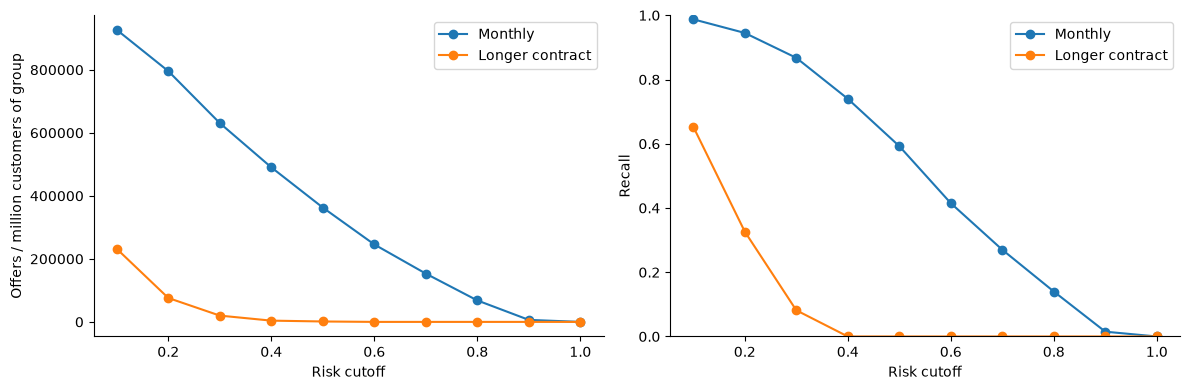

In [16]:
# Separate offer volume from recall because one is a campaign total and one is a rate.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Compare both groups using the same horizontal cutoff scale.
for name, in_group in groups.items():
    # Retrieve actual results for this group.
    group_results = group_cutoffs_raw[group_cutoffs_raw['Group'] == name]
    # Convert offer totals to the reporting basis for this group.
    scaled = per_million(group_results, int(in_group.sum()))
    # Show how lowering the cutoff expands the offer population.
    axes[0].plot(group_results['Cutoff'], scaled['Offers / million'], marker='o', label=name)
    # Recall retains its natural zero-to-one scale.
    axes[1].plot(group_results['Cutoff'], group_results['Recall'], marker='o', label=name)
# Label the count panel with its within-group denominator.
axes[0].set(xlabel='Risk cutoff', ylabel='Offers / million customers of group')
# Use the complete recall range rather than magnifying small changes.
axes[1].set(xlabel='Risk cutoff', ylabel='Recall', ylim=(0, 1))
# Identify both groups in each panel.
for ax in axes:
    # The same group names apply to reach and detection.
    ax.legend()
# Leave enough space for the two vertical labels.
plt.tight_layout()
# Display the offer/detection trade-off.
plt.show()

In [17]:
# Retrieve the calculated results at the classroom's illustrative 0.5 cutoff.
at_half = group_cutoffs_raw[group_cutoffs_raw['Cutoff'] == .5].set_index('Group')
# Reference counts are verification targets, never inputs to model fitting.
class_tp = pd.Series({'Monthly': 237, 'Longer contract': 0})
# Divide by actual observed churns to express reference detection as recall.
class_recall = class_tp / summary['Actual churns']
# Compare calculated and reference rates on matching group names.
recall_check = pd.DataFrame({'Calculated recall at 0.5': at_half['Recall'],
                             'Class recall at 0.5': class_recall})
# Keep both values visible, including the zero detection rate for longer contracts.
display(recall_check)

,Calculated recall at 0.5,Class recall at 0.5
Monthly,0.5925,0.5925
Longer contract,0.0000,0.0000


At cutoff 0.5, zero detections among longer contracts does **not** mean zero churns, nor does it prove miscalibration. Probabilities may be well below 0.5 even when events occur. Lowering the cutoff raises reach and usually FP as well as TP. Missed churn loses a retention opportunity; unnecessary discounts consume margin. Which error matters more depends on the intervention and economics, not just the classifier.

**Possible decisions:** accept the model for the intended use, review uncertain regions, reject it if the evidence fails a predeclared requirement, investigate different thresholds, or restrict use to supported populations. These data do not automatically justify excluding longer contracts. A restriction or group-specific threshold chosen after this exploration needs independent evaluation, including its economic and customer consequences.

**Takeaway:** Separate calibration, detection and support. Notebook 11 values fixed policies under explicit assumptions. Session 7 investigates explanations for group and individual differences; Session 8 validates incoming contract categories and monitors calibration, recall and value by group. A shift in contract mix can change a global metric without changing either group's behavior.

### Read the executed evidence
At cutoff 0.5 the monthly-contract recall is 59.25% (237 of the 400 observed churns), while longer-contract recall is 0% among 49 observed churns. These are actual-sample detection checks; the campaign tables above use per-million units. Both match the classroom observation.

The longer-contract [0.5, 0.625) bin has only one customer and zero churns; its Wilson upper bound is about 79.3%. The [0.375, 0.5) bin has four customers and zero churns, with an upper bound about 49.0%. Those data are too sparse to claim that these customers have no risk. A lower cutoff may improve detection, but its discount costs and any group-specific rule need separate evaluation.